In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

# Load dataset
df = pd.read_csv(
    r"C:\Users\purva\OneDrive\Desktop\lp3\dataset\uber.csv (1)\uber.csv"
)

print("Dataset Shape:", df.shape)

print("Dataset shape:", df.shape)
display(df.head())
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (200000, 9)
Dataset shape: (200000, 9)


,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  object 
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  object 
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), object(2)
memory usage: 13.7+ MB

Missing Values:
Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64


In [3]:
# Remove unnecessary columns
df = df.drop(columns=["Unnamed: 0", "key"], errors="ignore")

# Convert pickup_datetime into datetime format
df["pickup_datetime"] = pd.to_datetime(
    df["pickup_datetime"], errors="coerce"
)

# Remove missing values
df = df.dropna()

# Remove invalid records
df = df[
    (df["fare_amount"] > 0) &
    (df["passenger_count"] > 0) &
    (df["pickup_longitude"].between(-75, -72)) &
    (df["dropoff_longitude"].between(-75, -72)) &
    (df["pickup_latitude"].between(40, 42)) &
    (df["dropoff_latitude"].between(40, 42))
].copy()

# Extract time features
df["hour"] = df["pickup_datetime"].dt.hour
df["day"] = df["pickup_datetime"].dt.day
df["month"] = df["pickup_datetime"].dt.month

print("Dataset after preprocessing:", df.shape)
print("\nRemaining Missing Values:")
print(df.isnull().sum())

Dataset after preprocessing: (195101, 10)

Remaining Missing Values:
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    0
dropoff_latitude     0
passenger_count      0
hour                 0
day                  0
month                0
dtype: int64


Number of Outliers: 16708
Dataset after removing outliers: (178393, 10)


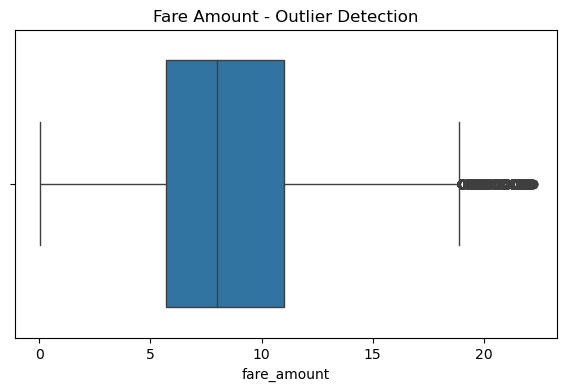

In [4]:
# Calculate Q1 and Q3
Q1 = df["fare_amount"].quantile(0.25)
Q3 = df["fare_amount"].quantile(0.75)

# Calculate IQR
IQR = Q3 - Q1

# Calculate lower and upper limits
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# Identify outliers
outliers = df[
    (df["fare_amount"] < lower) |
    (df["fare_amount"] > upper)
]

print("Number of Outliers:", len(outliers))

# Remove outliers
df = df[
    (df["fare_amount"] >= lower) &
    (df["fare_amount"] <= upper)
].copy()

print("Dataset after removing outliers:", df.shape)

# Visualize outliers using boxplot
plt.figure(figsize=(7, 4))
sns.boxplot(x=df["fare_amount"])
plt.title("Fare Amount - Outlier Detection")
plt.show()

Correlation Matrix:
                   fare_amount  pickup_longitude  pickup_latitude  \
fare_amount           1.000000          0.001260        -0.075713   
pickup_longitude      0.001260          1.000000         0.506694   
pickup_latitude      -0.075713          0.506694         1.000000   
dropoff_longitude     0.073956          0.708428         0.318101   
dropoff_latitude     -0.086856          0.323858         0.638140   
passenger_count       0.012200         -0.010974        -0.009126   
hour                 -0.012955          0.001305         0.032034   
day                   0.006983         -0.002368        -0.000827   
month                 0.026865          0.003633         0.001354   

                   dropoff_longitude  dropoff_latitude  passenger_count  \
fare_amount                 0.073956         -0.086856         0.012200   
pickup_longitude            0.708428          0.323858        -0.010974   
pickup_latitude             0.318101          0.638140        -0

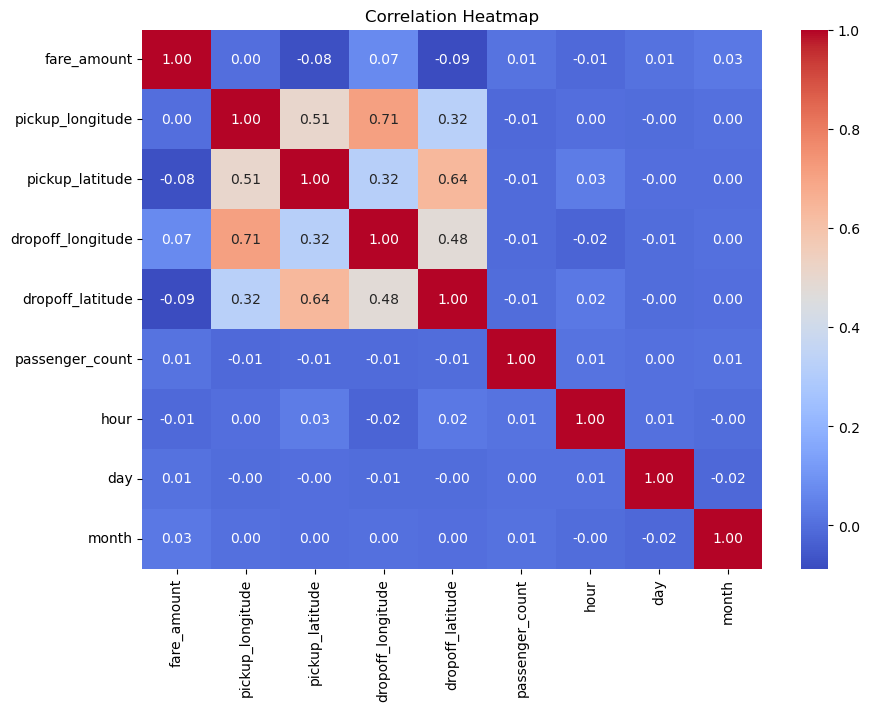

In [5]:
# Select numerical columns
numeric_df = df.select_dtypes(include="number")

# Calculate correlation
correlation = numeric_df.corr()

print("Correlation Matrix:")
print(correlation)

# Visualize correlation
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [8]:
print("Starting model training...")

# Use a smaller sample to speed up training
X_sample = X.sample(n=min(20000, len(X)), random_state=42)
y_sample = y.loc[X_sample.index]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X_sample, y_sample, test_size=0.2, random_state=42
)

# Linear Regression
print("\nTraining Linear Regression...")
lr = LinearRegression()
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)

print("Linear Regression completed!")

# Random Forest
print("\nTraining Random Forest...")
rf = RandomForestRegressor(
    n_estimators=20,
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

print("Random Forest completed!")

# Evaluation
lr_r2 = r2_score(y_test, lr_pred)
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_pred))
lr_mae = mean_absolute_error(y_test, lr_pred)

rf_r2 = r2_score(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_mae = mean_absolute_error(y_test, rf_pred)

# Comparison
comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "R2 Score": [lr_r2, rf_r2],
    "RMSE": [lr_rmse, rf_rmse],
    "MAE": [lr_mae, rf_mae]
})

print("\nFINAL MODEL COMPARISON:")
print(comparison.round(3))

if rf_r2 > lr_r2:
    print("\nRandom Forest performs better based on R2 Score.")
else:
    print("\nLinear Regression performs better based on R2 Score.")

Starting model training...

Training Linear Regression...
Linear Regression completed!

Training Random Forest...
Random Forest completed!

FINAL MODEL COMPARISON:
               Model  R2 Score   RMSE    MAE
0  Linear Regression     0.025  4.085  3.219
1      Random Forest     0.667  2.387  1.712

Random Forest performs better based on R2 Score.
